# 03 - Model comparison

Everything here is read back from the MLflow tracking store (`mlflow.db`, experiment `bank-churn`) written by `python -m src.models.train`.
Nothing is retrained in this notebook.

**How the comparison was run**
- Three models tuned with 5-fold stratified cross-validation on the **train split only**: logistic regression (scaled, reference dummies France and Female dropped, `class_weight="balanced"`),
  random forest (`class_weight="balanced"`, randomized search of 12 settings) and XGBoost (`scale_pos_weight` from the train class ratio, randomized search of 20 settings).
- **Selection rule, fixed in advance:** highest mean CV PR-AUC. Not test performance, not accuracy.
- The chosen model was then calibrated (`CalibratedClassifierCV`, 5-fold on train) so its scores behave like probabilities, which Stage 5 needs when it multiplies them by balances.
- The **test split was loaded only after selection and calibration**, and each model was scored on it once.

In [1]:
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import display
from mlflow import MlflowClient
from sklearn.metrics import brier_score_loss, roc_auc_score

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
mlflow.set_tracking_uri(f"sqlite:///{(root / 'mlflow.db').as_posix()}")
client = MlflowClient()

runs = mlflow.search_runs(experiment_names=["bank-churn"], filter_string="tags.stage = '4'")
NAMES = {"logistic_regression": "Logistic regression", "random_forest": "Random forest",
         "xgboost": "XGBoost", "xgboost_calibrated": "XGBoost (calibrated)"}
runs["model"] = runs["tags.mlflow.runName"].map(NAMES)
runs = runs.set_index("model").loc[list(NAMES.values())]

table = pd.DataFrame({
    "CV PR-AUC": runs["metrics.cv_pr_auc_mean"], "CV PR-AUC std": runs["metrics.cv_pr_auc_std"],
    "CV ROC-AUC": runs["metrics.cv_roc_auc_mean"],
    "Test ROC-AUC": runs["metrics.test_roc_auc"], "Test PR-AUC": runs["metrics.test_pr_auc"],
    "Test Brier": runs["metrics.test_brier"],
    "Precision @0.5": runs["metrics.test_precision_at_0.5"], "Recall @0.5": runs["metrics.test_recall_at_0.5"],
    "Lift top 10%": runs["metrics.test_lift_top10"], "Lift top 20%": runs["metrics.test_lift_top20"],
})
display(table.round(4))


def with_ci(metric):
    return runs.apply(lambda r: f"{r[f'metrics.test_{metric}']:.3f} [{r[f'metrics.test_{metric}_ci_low']:.3f}, "
                                f"{r[f'metrics.test_{metric}_ci_high']:.3f}]", axis=1)


print("Test metrics with bootstrap 95% confidence intervals:")
display(pd.DataFrame({"Test ROC-AUC": with_ci("roc_auc"), "Test PR-AUC": with_ci("pr_auc"), "Test Brier": with_ci("brier")}))

parent = mlflow.search_runs(experiment_names=["bank-churn"], filter_string="tags.mlflow.runName = 'stage4-training'").iloc[0]
print(f"Selected by mean CV PR-AUC: {parent['params.selected_model']}; calibration method: {parent['params.calibration_method']} "
      f"(CV Brier: sigmoid {parent['metrics.calibration_cv_brier_sigmoid']:.4f}, isotonic {parent['metrics.calibration_cv_brier_isotonic']:.4f})")

,CV PR-AUC,CV PR-AUC std,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Test Brier,Precision @0.5,Recall @0.5,Lift top 10%,Lift top 20%
model,,,,,,,,,,
Logistic regression,0.4758,0.0148,0.7652,0.7460,0.4438,0.2042,0.3795,0.6536,2.7764,2.2482
Random forest,0.6910,0.0177,0.8595,0.8657,0.6797,0.1309,0.5377,0.7002,3.9558,3.0221
XGBoost,0.7062,0.0155,0.8647,0.8649,0.6964,0.1388,0.5153,0.7469,3.9312,3.0713
XGBoost (calibrated),0.7062,0.0155,0.8647,0.8646,0.6949,0.1034,0.7419,0.4521,3.9312,3.0713


Test metrics with bootstrap 95% confidence intervals:


,Test ROC-AUC,Test PR-AUC,Test Brier
model,,,
Logistic regression,"0.746 [0.720, 0.771]","0.444 [0.397, 0.496]","0.204 [0.198, 0.211]"
Random forest,"0.866 [0.844, 0.884]","0.680 [0.630, 0.722]","0.131 [0.123, 0.140]"
XGBoost,"0.865 [0.844, 0.884]","0.696 [0.650, 0.736]","0.139 [0.131, 0.147]"
XGBoost (calibrated),"0.865 [0.843, 0.883]","0.695 [0.649, 0.735]","0.103 [0.094, 0.113]"


Selected by mean CV PR-AUC: xgboost; calibration method: isotonic (CV Brier: sigmoid 0.1029, isotonic 0.1012)


Column guide: **CV** columns come from 5-fold cross-validation on train; everything else is the single scoring on the held-out test split.
**Brier** is the mean squared error of the predicted probability (lower is better; 0.25 is a model that always says 50%).
**Lift top 10% / 20%** is the churn rate among the customers with the highest scores divided by the overall churn rate.
Precision and recall at 0.5 are shown only because they were requested; the real threshold is chosen in Stage 5.

**95% confidence intervals** are percentile intervals from 1,000 bootstrap resamples of the test customers, with every model scored on the same resamples.
They capture test-set sampling noise only (the fitted models are held fixed), not the variation you would get from retraining or from a different split.

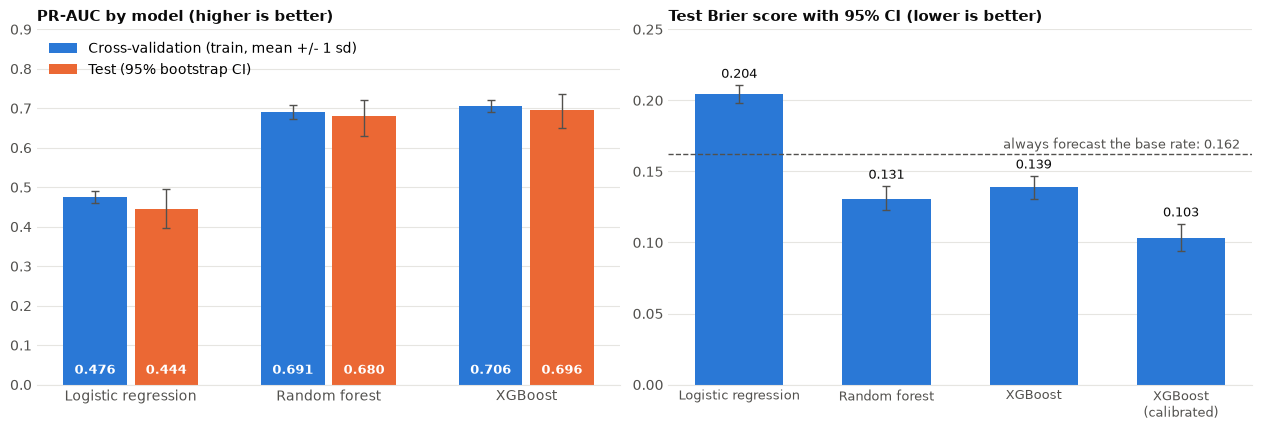

Paired bootstrap on the test set, xgboost minus random_forest (same resampled customers for both models):
  ROC-AUC  -0.0008   95% CI [-0.0073, +0.0056]
  PR-AUC   +0.0169   95% CI [+0.0027, +0.0314]
  Brier    +0.0078   95% CI [+0.0049, +0.0108]


In [2]:
INK, MUTED, GRID, BLUE, ORANGE = "#0b0b0b", "#52514e", "#e6e5e1", "#2a78d6", "#eb6834"


def style(ax, title):
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2), constrained_layout=True)

cand = table.iloc[:3]
x, w = np.arange(3), 0.36
ax1.bar(x - w / 2, cand["CV PR-AUC"], w - 0.04, yerr=cand["CV PR-AUC std"], color=BLUE, label="Cross-validation (train, mean +/- 1 sd)",
        error_kw={"ecolor": MUTED, "lw": 1, "capsize": 3})
def err(metric, rows):
    v = runs[f"metrics.test_{metric}"].loc[rows]
    return np.vstack([v - runs[f"metrics.test_{metric}_ci_low"].loc[rows], runs[f"metrics.test_{metric}_ci_high"].loc[rows] - v])


ax1.bar(x + w / 2, cand["Test PR-AUC"], w - 0.04, yerr=err("pr_auc", cand.index), color=ORANGE, label="Test (95% bootstrap CI)",
        error_kw={"ecolor": MUTED, "lw": 1, "capsize": 3})
for xs, vals in ((x - w / 2, cand["CV PR-AUC"]), (x + w / 2, cand["Test PR-AUC"])):
    for xi, v in zip(xs, vals):
        ax1.text(xi, 0.02, f"{v:.3f}", ha="center", va="bottom", color="white", fontsize=9, fontweight="bold")
ax1.set_xticks(x, cand.index, color=MUTED)
ax1.set_ylim(0, 0.9)
ax1.legend(frameon=False, loc="upper left")
style(ax1, "PR-AUC by model (higher is better)")

rate = pd.read_parquet(root / "data" / "processed" / "features.parquet").query("split == 'test'")["Exited"].mean()
const_brier = rate * (1 - rate)
ax2.axhline(const_brier, ls="--", color=MUTED, lw=1)
ax2.text(3.4, const_brier + 0.004, f"always forecast the base rate: {const_brier:.3f}", ha="right", color=MUTED, fontsize=9)
ax2.bar(np.arange(4), table["Test Brier"], 0.6, yerr=err("brier", table.index), color=BLUE,
        error_kw={"ecolor": MUTED, "lw": 1, "capsize": 3})
for i, (v, hi) in enumerate(zip(table["Test Brier"], runs["metrics.test_brier_ci_high"])):
    ax2.text(i, hi + 0.003, f"{v:.3f}", ha="center", va="bottom", color=INK, fontsize=9)
ax2.set_xticks(np.arange(4), [n.replace(" (", "\n(") for n in table.index], color=MUTED, fontsize=9)
ax2.set_ylim(0, 0.25)
style(ax2, "Test Brier score with 95% CI (lower is better)")
plt.show()

pair = parent["params.paired_diff_pair"]
print(f"Paired bootstrap on the test set, {pair} (same resampled customers for both models):")
for m, label in (("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("brier", "Brier")):
    print(f"  {label:8s} {parent[f'metrics.paired_diff_{m}_mean']:+.4f}   95% CI [{parent[f'metrics.paired_diff_{m}_ci_low']:+.4f}, "
          f"{parent[f'metrics.paired_diff_{m}_ci_high']:+.4f}]")

## The champion's diagnostics
Saved by the training run as MLflow artifacts for the calibrated XGBoost model (test split). The calibration panel compares the model before and after calibration.

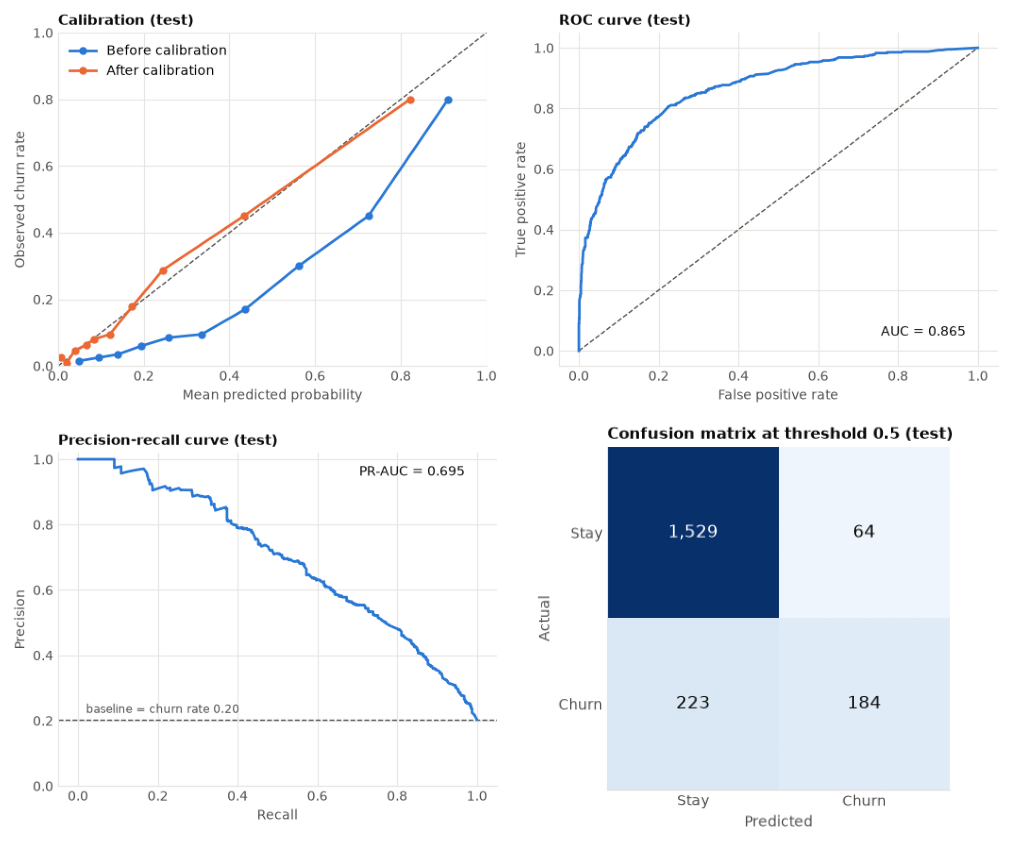

In [3]:
champ = client.get_model_version("bank-churn-model", "1")  # the Stage 4 champion; later versions are Stage 5
fig, axes = plt.subplots(2, 2, figsize=(10, 8.4), constrained_layout=True)
for ax, name in zip(axes.ravel(), ["calibration", "roc", "pr", "confusion_matrix"]):
    path = mlflow.artifacts.download_artifacts(run_id=champ.run_id, artifact_path=f"plots/{name}.png")
    ax.imshow(mpimg.imread(path))
    ax.axis("off")
plt.show()

## Registry check
Loads registered **version 1** of the model (the Stage 4 champion, which uses all 18 features including Gender) and confirms it reproduces the logged test metrics.
In Stage 5 an ablation showed Gender adds nothing measurable, and a no-Gender model was registered as version 2 and given the `champion` alias; version 1 is kept for comparison, which is why it is loaded by version number here.
This is a consistency check on the registered artifact, not a new model evaluation.

In [4]:
print(f"models:/bank-churn-model/1 -> version {champ.version} (run {str(champ.run_id)[:8]})")
model = mlflow.pyfunc.load_model("models:/bank-churn-model/1")
print("input columns:", len(model.metadata.signature.inputs.inputs), "| output:", model.metadata.signature.outputs)

df = pd.read_parquet(root / "data" / "processed" / "features.parquet")
test = df[df["split"] == "test"]
p = model.predict(test.drop(columns=["Exited", "split"]))[:, 1]
y = test["Exited"].to_numpy()
print(f"reloaded test ROC-AUC {roc_auc_score(y, p):.4f} (logged {runs.loc['XGBoost (calibrated)', 'metrics.test_roc_auc']:.4f}), "
      f"Brier {brier_score_loss(y, p):.4f} (logged {runs.loc['XGBoost (calibrated)', 'metrics.test_brier']:.4f})")
print(f"Brier of a constant forecast of the base rate ({y.mean():.3f}): {y.mean() * (1 - y.mean()):.4f}")

models:/bank-churn-model/1 -> version 1 (run c71682d0)


input columns: 18 | output: [Tensor('float64', (-1, 2))]
reloaded test ROC-AUC 0.8646 (logged 0.8646), Brier 0.1034 (logged 0.1034)
Brier of a constant forecast of the base rate (0.203): 0.1621


## Why XGBoost won

**The rule picked it, narrowly over the random forest.** XGBoost had the highest mean CV PR-AUC (0.706, against 0.691 for the random forest and 0.476 for logistic regression).
PR-AUC is the right yardstick here because only about one customer in five churns and the question is how well the model ranks the churners above everyone else; accuracy would reward predicting "stays" for everyone.

**Be honest about the margin.** The cross-validation gap between XGBoost and the random forest (0.015) is about one fold-to-fold standard deviation (0.016 to 0.018), so on the training data they are close to a tie.
On the test split, the paired bootstrap above shows ROC-AUC is a tie (difference -0.001, 95% CI -0.007 to +0.006), while PR-AUC favours XGBoost by about 0.017 (95% CI +0.003 to +0.031):
small, but distinguishable from zero for these two fitted models on this test set. The single-model intervals in the table overlap heavily (PR-AUC 0.63 to 0.72 for the forest, 0.65 to 0.74 for XGBoost);
the paired interval is much tighter because both models are scored on the same resampled customers.
Before calibration XGBoost's Brier score is worse than the forest's (+0.008, CI +0.005 to +0.011), which is the inflated-probability effect of class weighting that the calibration step fixes.
The bootstrap only reflects noise from which customers landed in the test set (407 churners); it says nothing about retraining variability, so treat the PR-AUC edge as modest.
XGBoost was chosen because the selection rule was fixed before looking at the test split, and the random forest remains a reasonable alternative.

**Logistic regression is far behind, and not because of tuning.** Widening the C grid from 1e-6 to 1e2 gave the same optimum (C = 0.001), with a flat curve. The limit is the model form: churn is not linear in the inputs.
Number of products is U-shaped (2 products churn least, 1 product and 3-4 products churn far more), age peaks at 50-59 and falls again at 60+, and geography interacts with activity.
Trees capture these shapes and interactions without hand-built features; the linear model cannot.

**Calibration was needed, and it worked.** Weighting the minority class (`scale_pos_weight`) pushes predicted probabilities up, so the raw XGBoost scores overstate churn risk: a score near 0.43 corresponded to roughly 17% actual churn (calibration panel above).
After isotonic calibration (chosen over sigmoid by cross-validated Brier score on train, 0.1012 vs 0.1029) the test Brier score fell from 0.139 (95% CI 0.131 to 0.147) to 0.103 (0.094 to 0.113), intervals that do not overlap and sit well below the 0.162 of simply forecasting the base rate, while ranking quality was unchanged (ROC-AUC 0.865, PR-AUC 0.695).
Probabilities that are real probabilities are what Stage 5 needs to multiply by balances.

**Reading the results.** The top 10% of customers by score churn at about 3.9 times the base rate (roughly 80% against 20%), and the top 20% at about 3.1 times (roughly 62%).
At the default 0.5 cut-off the calibrated model is cautious: when it flags a customer it is right 74% of the time but it catches only 45% of churners. That is a threshold question, not a model-quality one, and it is handled in Stage 5.

**Caveats.** One 80/20 split and a single seed: test figures carry sampling error, and the Stage 4 champion is registered as v1 of `bank-churn-model`. It has since been superseded by v2 (the same setup without Gender, see notebook 04), which now holds the `champion` alias.
Importance, explanations, thresholds and ROI are deliberately not covered yet; they belong to Stage 5.